# Student Depression Analysis with Logistic Regression

**Author:** Miguel Estrada

## Project objective
Explore a student-depression dataset and build a **Logistic Regression** classification model to predict the recorded `Depression` outcome from the available demographic, academic, social, and health-related variables.

> **Important:** This is an educational data-analysis project. It does not diagnose depression, establish causes, or replace professional mental-health assessment. The dataset's labels and relationships should not be interpreted as clinical conclusions.

## Notebook outline
1. Load and inspect the data
2. Data quality checks
3. Exploratory data analysis (EDA)
4. Prepare the target and predictor variables
5. Encode categorical variables and scale numerical variables
6. Train Logistic Regression
7. Evaluate classification performance
8. Interpret coefficients and odds ratios
9. Summarize findings and limitations

The notebook expects `Student_Depression_Dataset.csv` to be in the same folder.

In [1]:
# Imports
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

In [2]:
# 1. Load the dataset
data = pd.read_csv("Student_Depression_Dataset.csv")

print(f"Dataset shape: {data.shape[0]:,} rows × {data.shape[1]} columns")
display(data.head())

Dataset shape: 4,464 rows × 13 columns


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [3]:
# 2. Dataset overview and data quality
display(data.info())

print("\\nMissing values by column:")
display(data.isna().sum().to_frame("Missing values"))

print(f"\\nExact duplicate rows: {data.duplicated().sum():,}")
print("\\nTarget distribution:")
display(data["Depression"].value_counts(dropna=False).to_frame("Count"))
display(
    (data["Depression"].value_counts(normalize=True, dropna=False) * 100)
    .round(2).to_frame("Percentage")
)

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 453.5 KB


None

\nMissing values by column:


,Missing values
Gender,0
Age,0
Family_background,0
Relationship_status,0
Marital_status,0
Living_style,0
Current_semester,0
CGPA,0
friend_circle,0
Health_condition,0


\nExact duplicate rows: 0
\nTarget distribution:


,Count
Depression,
No,3263
Yes,1201


,Percentage
Depression,
No,73.1
Yes,26.9


In [4]:
# Validate the expected target labels and inspect categorical values
target_labels = set(data["Depression"].dropna().unique())
expected_labels = {"No", "Yes"}

if not target_labels.issubset(expected_labels):
    raise ValueError(f"Unexpected Depression labels: {target_labels}")

categorical_columns = data.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_columns = data.select_dtypes(include=np.number).columns.tolist()

print("Categorical columns:", categorical_columns)
print("Numerical columns:", numerical_columns)

for column in categorical_columns:
    print(f"\\n{column}:")
    display(data[column].value_counts(dropna=False).to_frame("Count"))

Categorical columns: ['Gender', 'Family_background', 'Relationship_status', 'Marital_status', 'Living_style', 'friend_circle', 'Health_condition', 'Home_division', 'Depression']
Numerical columns: ['Age', 'Current_semester', 'CGPA', 'Cost_without_study']
\nGender:


C:\Users\Miguel Estrada\AppData\Local\Temp\ipykernel_3184\471079793.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = data.select_dtypes(include=["object", "category"]).columns.tolist()


,Count
Gender,
Female,2462
Male,2002


\nFamily_background:


,Count
Family_background,
Middle class,2642
Lower Middle class,1151
Rich class,671


\nRelationship_status:


... (9 outputs left out)

\nHome_division:


,Count
Home_division,
Dhaka,1527
Khulna,548
Rajshahi,488
Sylhet,445
Chittagong,400
Rangpur,363
Barisal,355
Mymensingh,338


\nDepression:


,Count
Depression,
No,3263
Yes,1201


## Exploratory Data Analysis (EDA)

The following plots describe the sample and show how selected variables are distributed across the recorded depression labels. These are descriptive comparisons, not evidence of causation.

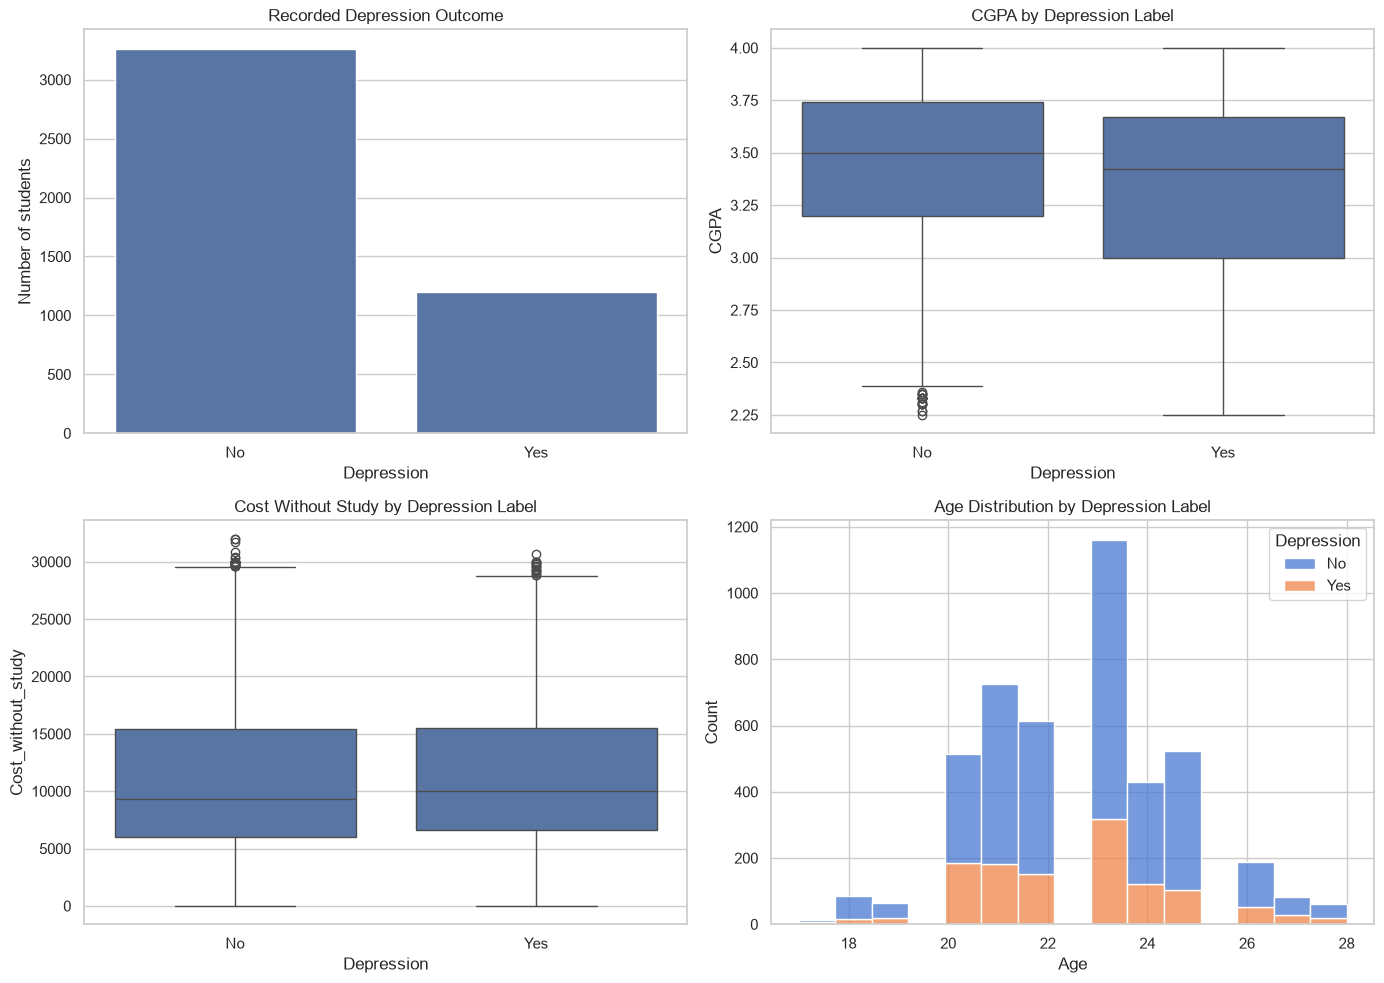

In [5]:
# 3. Target distribution and selected numerical features
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=data, x="Depression", order=["No", "Yes"], color="#4C72B0", ax=axes[0, 0])
axes[0, 0].set_title("Recorded Depression Outcome")
axes[0, 0].set_xlabel("Depression")
axes[0, 0].set_ylabel("Number of students")

sns.boxplot(data=data, x="Depression", y="CGPA", order=["No", "Yes"], color="#4C72B0", ax=axes[0, 1])
axes[0, 1].set_title("CGPA by Depression Label")

sns.boxplot(data=data, x="Depression", y="Cost_without_study", order=["No", "Yes"], color="#4C72B0", ax=axes[1, 0])
axes[1, 0].set_title("Cost Without Study by Depression Label")

sns.histplot(data=data, x="Age", hue="Depression", hue_order=["No", "Yes"],
             multiple="stack", bins=15, ax=axes[1, 1])
axes[1, 1].set_title("Age Distribution by Depression Label")

plt.tight_layout()
plt.show()

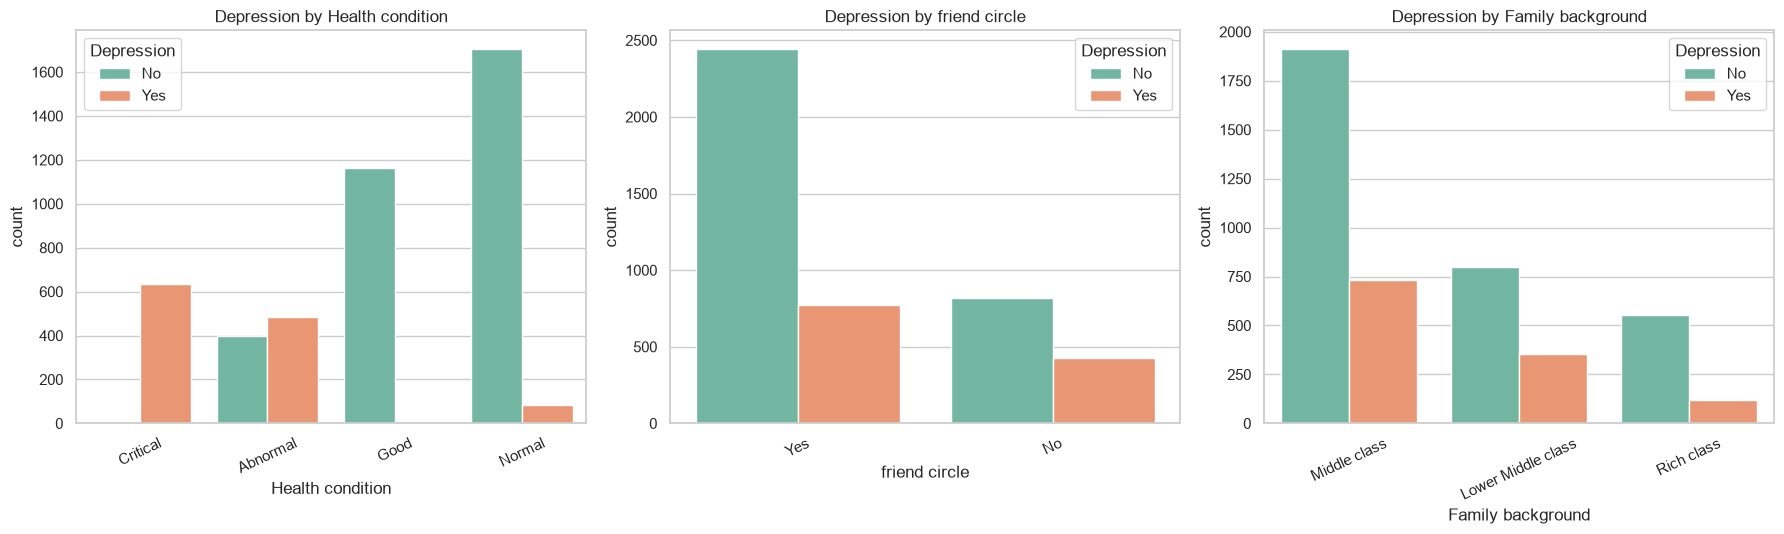

In [6]:
# 4. Depression label counts across selected categorical variables
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, column in zip(axes, ["Health_condition", "friend_circle", "Family_background"]):
    sns.countplot(data=data, x=column, hue="Depression", hue_order=["No", "Yes"], palette="Set2", ax=ax)
    ax.set_title(f"Depression by {column.replace('_', ' ')}")
    ax.set_xlabel(column.replace("_", " "))
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

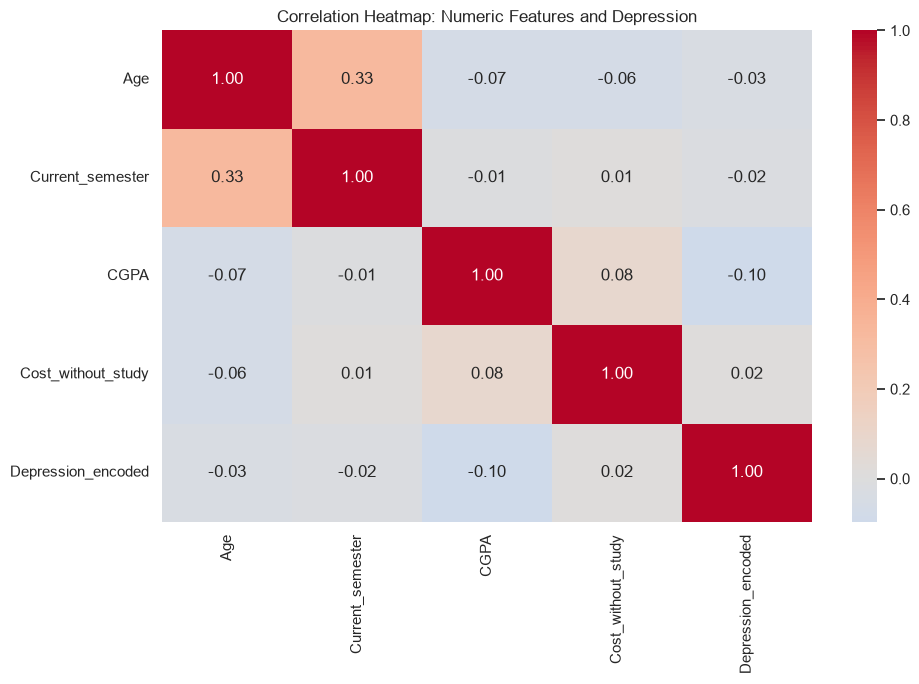

In [7]:
# 5. Correlation heatmap for numerical variables and the explicitly encoded target
# Target mapping is fixed and documented below: No = 0, Yes = 1.
target_mapping = {"No": 0, "Yes": 1}

numeric_for_corr = data[numerical_columns].copy()
numeric_for_corr["Depression_encoded"] = data["Depression"].map(target_mapping)

plt.figure(figsize=(10, 7))
sns.heatmap(numeric_for_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap: Numeric Features and Depression")
plt.tight_layout()
plt.show()

## Model preparation

The target is mapped explicitly rather than using `LabelEncoder`:

| Original target value | Numeric code | Meaning |
|---|---:|---|
| `No` | 0 | The dataset records no depression |
| `Yes` | 1 | The dataset records depression |

Categorical predictor variables are handled with **One-Hot Encoding**. This creates a separate indicator column for each category (with one reference category dropped per variable to avoid redundant columns). Numerical variables are standardized using statistics learned from the training set.

Preprocessing is placed inside a Scikit-learn `Pipeline` to avoid fitting preprocessing on the test data.

In [8]:
# 6. Split features and target
# Explicitly document the target encoding
y = data["Depression"].map(target_mapping).astype(int)
X = data.drop(columns=["Depression"]).copy()

# Identify feature types from X only
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

print("Target encoding:")
print(target_mapping)
print("\\nNumeric features:", numeric_features)
print("Categorical features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print(f"Training rows: {len(X_train):,}")
print(f"Testing rows:  {len(X_test):,}")

Target encoding:
{'No': 0, 'Yes': 1}
\nNumeric features: ['Age', 'Current_semester', 'CGPA', 'Cost_without_study']
Categorical features: ['Gender', 'Family_background', 'Relationship_status', 'Marital_status', 'Living_style', 'friend_circle', 'Health_condition', 'Home_division']
Training rows: 3,571
Testing rows:  893


C:\Users\Miguel Estrada\AppData\Local\Temp\ipykernel_3184\2772606036.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()


In [9]:
# 7. Preprocessing and Logistic Regression pipeline
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first")),
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42,
    )),
])

model.fit(X_train, y_train)
print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [11]:
# 8. Predict labels and probabilities
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("Predicted label codes:", sorted(np.unique(y_pred)))
print("Probability values represent the model-estimated probability of target code 1 (Yes).")

Predicted label codes: [np.int64(0), np.int64(1)]
Probability values represent the model-estimated probability of target code 1 (Yes).


In [12]:
# 9. Classification metrics
metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced accuracy",
        "Precision (Yes)",
        "Recall (Yes)",
        "F1-score (Yes)",
        "ROC-AUC",
        "Average precision",
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        balanced_accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_proba),
        average_precision_score(y_test, y_proba),
    ],
})

display(metrics.round(4))
print("\\nClassification report (target code 0 = No, 1 = Yes):")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No (0)", "Yes (1)"],
    zero_division=0,
))

,Metric,Score
0,Accuracy,0.9709
1,Balanced accuracy,0.9682
2,Precision (Yes),0.9315
3,Recall (Yes),0.9625
4,F1-score (Yes),0.9467
5,ROC-AUC,0.9933
6,Average precision,0.9867


\nClassification report (target code 0 = No, 1 = Yes):
              precision    recall  f1-score   support

      No (0)       0.99      0.97      0.98       653
     Yes (1)       0.93      0.96      0.95       240

    accuracy                           0.97       893
   macro avg       0.96      0.97      0.96       893
weighted avg       0.97      0.97      0.97       893



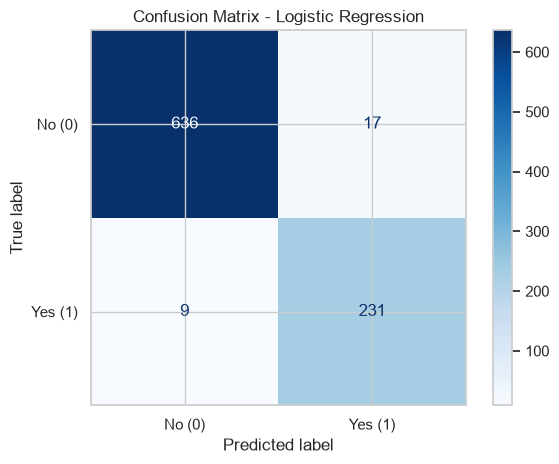

Confusion matrix layout:
Rows = actual labels; columns = predicted labels.
TN (top-left), FP (top-right), FN (bottom-left), TP (bottom-right).


In [13]:
# 10. Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No (0)", "Yes (1)"],
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

print("Confusion matrix layout:")
print("Rows = actual labels; columns = predicted labels.")
print("TN (top-left), FP (top-right), FN (bottom-left), TP (bottom-right).")

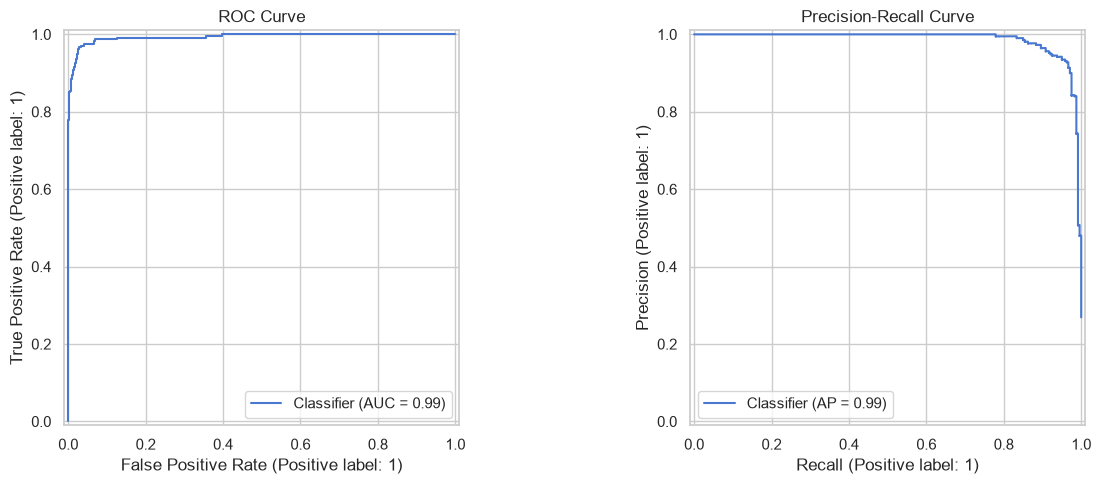

In [14]:
# 11. ROC and Precision-Recall curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[0])
axes[0].set_title("ROC Curve")

PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[1].set_title("Precision-Recall Curve")

plt.tight_layout()
plt.show()

## Coefficients, odds ratios, and feature importance

Logistic Regression coefficients are expressed in log-odds:

- **Positive coefficient:** associated with higher model-estimated odds of the `Yes` outcome, holding other encoded features constant.
- **Negative coefficient:** associated with lower model-estimated odds of the `Yes` outcome, holding other encoded features constant.
- **Odds ratio:** `exp(coefficient)`. For standardized numerical features, it corresponds to a one-standard-deviation increase. For a one-hot category, it compares that category with its dropped reference category.
- **Relative coefficient magnitude:** absolute coefficient divided by the sum of absolute coefficients. This is a model-based descriptive ranking, not causal importance.

Because numeric features are standardized, their coefficient scales are more comparable. Categorical coefficients represent comparisons against a reference category, so interpret them accordingly.

In [15]:
# 12. Extract transformed feature names and coefficients
fitted_preprocessor = model.named_steps["preprocessor"]
fitted_classifier = model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = fitted_classifier.coef_[0]

coefficient_analysis = pd.DataFrame({
    "Encoded feature": feature_names,
    "Coefficient": coefficients,
})

coefficient_analysis["Absolute coefficient"] = coefficient_analysis["Coefficient"].abs()
coefficient_analysis["Odds ratio"] = np.exp(coefficient_analysis["Coefficient"])
total_abs_coef = coefficient_analysis["Absolute coefficient"].sum()

coefficient_analysis["Relative coefficient magnitude (%)"] = (
    coefficient_analysis["Absolute coefficient"] / total_abs_coef * 100
)

coefficient_analysis = coefficient_analysis.sort_values(
    "Absolute coefficient", ascending=False
).reset_index(drop=True)

display(coefficient_analysis.round(4))

,Encoded feature,Coefficient,Absolute coefficient,Odds ratio,Relative coefficient magnitude (%)
0,categorical__Health_condition_Critical,7.6682,7.6682,2139.2296,21.1791
1,categorical__Health_condition_Good,-7.4808,7.4808,0.0006,20.6616
2,categorical__Health_condition_Normal,-4.9434,4.9434,0.0071,13.6535
3,categorical__Relationship_status_Single,2.4903,2.4903,12.0648,6.8781
4,categorical__Relationship_status_In a Relation...,-2.4829,2.4829,0.0835,6.8575
5,categorical__Marital_status_Unmarried,2.4466,2.4466,11.5489,6.7573
6,categorical__friend_circle_Yes,-1.8239,1.8239,0.1614,5.0375
7,categorical__Family_background_Rich class,-1.3976,1.3976,0.2472,3.8600
8,categorical__Marital_status_Separated,1.0167,1.0167,2.7642,2.8082
9,numeric__CGPA,-0.6539,0.6539,0.5200,1.8060


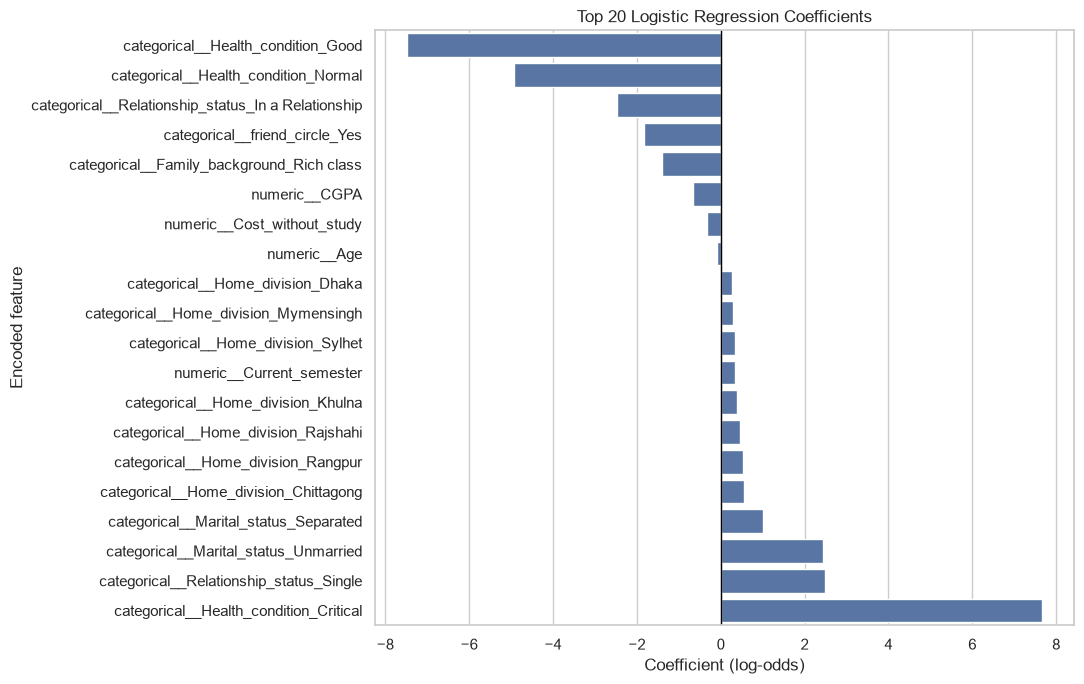

In [16]:
# 13. Plot the largest coefficient magnitudes
top_n = min(20, len(coefficient_analysis))
top_features = coefficient_analysis.head(top_n).sort_values("Coefficient")

plt.figure(figsize=(11, max(6, top_n * 0.35)))
sns.barplot(data=top_features, x="Coefficient", y="Encoded feature", color="#4C72B0")
plt.axvline(0, color="black", linewidth=1)
plt.title(f"Top {top_n} Logistic Regression Coefficients")
plt.xlabel("Coefficient (log-odds)")
plt.ylabel("Encoded feature")
plt.tight_layout()
plt.show()

In [17]:
# 14. Show the exact category encoding and reference categories
# OneHotEncoder categories are learned from the training data only.
ohe = fitted_preprocessor.named_transformers_["categorical"].named_steps["onehot"]
category_encoding = []

for feature, categories in zip(categorical_features, ohe.categories_):
    dropped = ohe.drop_idx_
    drop_index = None if dropped is None else dropped[categorical_features.index(feature)]
    reference = None if drop_index is None else categories[drop_index]

    for category in categories:
        category_encoding.append({
            "Original column": feature,
            "Original category": category,
            "Encoded column": (
                f"categorical__{feature}_{category}"
                if category != reference
                else "Reference category (all dummy columns = 0)"
            ),
            "Reference category": reference,
        })

category_encoding_table = pd.DataFrame(category_encoding)
display(category_encoding_table)

print("\\nTarget label mapping:")
display(pd.DataFrame([
    {"Original target": "No", "Encoded value": 0, "Description": "Dataset label indicates no depression"},
    {"Original target": "Yes", "Encoded value": 1, "Description": "Dataset label indicates depression"},
]))

,Original column,Original category,Encoded column,Reference category
0,Gender,Female,Reference category (all dummy columns = 0),Female
1,Gender,Male,categorical__Gender_Male,Female
2,Family_background,Lower Middle class,Reference category (all dummy columns = 0),Lower Middle class
3,Family_background,Middle class,categorical__Family_background_Middle class,Lower Middle class
4,Family_background,Rich class,categorical__Family_background_Rich class,Lower Middle class
5,Relationship_status,Complicated,Reference category (all dummy columns = 0),Complicated
6,Relationship_status,In a Relationship,categorical__Relationship_status_In a Relation...,Complicated
7,Relationship_status,Single,categorical__Relationship_status_Single,Complicated
8,Marital_status,Married,Reference category (all dummy columns = 0),Married
9,Marital_status,Separated,categorical__Marital_status_Separated,Married


\nTarget label mapping:


,Original target,Encoded value,Description
0,No,0,Dataset label indicates no depression
1,Yes,1,Dataset label indicates depression


## Conclusions and interpretation

Use the metric table, confusion matrix, and coefficient table above to describe the model's performance. In particular:

- Review **recall for `Yes (1)`** to understand how many positive cases the model identifies.
- Review **precision for `Yes (1)`** to understand how often positive predictions are correct.
- Compare accuracy with balanced accuracy because the target classes are not equally represented.
- Treat the coefficient table as an association within this fitted model, not as a ranking of causes or risk factors.

## Limitations and responsible use

- The dataset is observational and may not represent all students or populations.
- The target is a dataset label, not a clinical diagnosis.
- Logistic Regression captures a linear relationship between predictors and log-odds unless interactions or nonlinear terms are added.
- `class_weight="balanced"` changes the training objective to account for class frequencies; the resulting probability estimates may need calibration for probability-focused use.
- No model should be used to label, screen, or make consequential decisions about an individual student without appropriate clinical, ethical, privacy, and validation safeguards.
- Check data provenance, measurement definitions, consent, and potential demographic bias before presenting results as generalizable.

**Project author:** Miguel Estrada